# A/B Testing Analysis: Landing Page Experiment

## Objective
An e-commerce company introduced a new landing page and conducted an A/B test to determine whether the redesign improves user conversion rates.

This project analyzes the experiment data using statistical testing and regression analysis to evaluate whether the new landing page leads to a statistically significant increase in conversions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

In [2]:
df=pd.read_csv("../data/ab_data.csv")
countries=pd.read_csv("../data/countries.csv")

In [3]:
print("Rows:", len(df))
print("Duplicate user rows:", df['user_id'].duplicated().sum())

Rows: 294478
Duplicate user rows: 3894


## Data Cleaning

Two problems can corrupt an A/B test:
1. **Mismatched rows**: users in the control group who saw the new page (or treatment users who saw the old page). We can't tell which experience they really had, so these rows are removed.
2. **Duplicate users**: the same user appearing more than once.

Order matters here. Most duplicate users have one valid row and one mismatched row. Removing mismatched rows **first** keeps the valid row. Removing duplicates first would sometimes keep the mismatched row and then throw that user away entirely.

## Step 1: Remove Mismatched Rows

In [4]:
df_mismatch=df[
((df['group']=='control')&(df['landing_page']=='new_page'))|
((df['group']=='treatment')&(df['landing_page']=='old_page'))]

df_mismatch.shape

(3893, 5)

In [5]:
df=df.drop(df_mismatch.index)

In [6]:
df_mismatch = df[
    ((df['group'] == 'control') & (df['landing_page'] == 'new_page')) |
    ((df['group'] == 'treatment') & (df['landing_page'] == 'old_page'))
]

df_mismatch.shape

(0, 5)

## Step 2: Remove Remaining Duplicate Users

In [7]:
df = df.drop_duplicates(subset='user_id')

In [8]:
df['user_id'].duplicated().sum()

np.int64(0)

In [9]:
df.groupby(['group','landing_page']).size()

group      landing_page
control    old_page        145274
treatment  new_page        145310
dtype: int64

In [10]:
df['converted'].mean()

np.float64(0.11959708724499628)

In [11]:
df.groupby('group')['converted'].mean()

group
control      0.120386
treatment    0.118808
Name: converted, dtype: float64

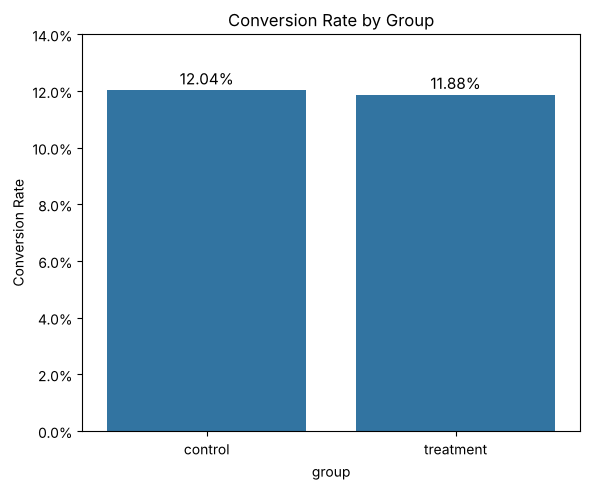

In [12]:
from matplotlib.ticker import PercentFormatter
conversion_rates = df.groupby('group')['converted'].mean().reset_index()
plt.figure(figsize=(6,5))

ax=sns.barplot(x='group', y='converted', data=conversion_rates)

plt.title("Conversion Rate by Group")
plt.ylabel("Conversion Rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0,0.14)

for i, row in conversion_rates.iterrows():
    ax.text(i, row['converted'] + 0.002, f"{row['converted']*100:.2f}%", 
            ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("../visuals/conversion_rate_by_group.png")

plt.show()

### Conversion Rate Analysis

The overall conversion rate of the dataset is approximately 11.96%.

When comparing the two experiment groups:
- Control group conversion rate: 12.04%
- Treatment group conversion rate: 11.88%

The control group (old landing page) shows a slightly higher conversion rate than the treatment group (new landing page). However, the difference is very small and requires statistical testing to determine whether it is statistically significant.

## Hypothesis Testing

I use a **two-sided** test, because the new page could make conversion better *or* worse, and both matter to the business.

**Null Hypothesis (H0):** The new page has the same conversion rate as the old page.

H0: p_new = p_old

**Alternative Hypothesis (H1):** The conversion rates are different.

H1: p_new ≠ p_old

Significance level: α = 0.05

In [13]:
convert_old = df[df['group']=='control']['converted'].sum()
convert_new = df[df['group']=='treatment']['converted'].sum()

convert_old, convert_new

(np.int64(17489), np.int64(17264))

In [14]:
n_old=df[df['group']=='control'].shape[0]
n_new=df[df['group']=='treatment'].shape[0]

n_old,n_new

(145274, 145310)

In [15]:
z_stat, p_value = proportions_ztest(
    [convert_new, convert_old],
    [n_new, n_old],
    alternative='two-sided'
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value:     {p_value:.4f}")

Z-statistic: -1.3109
P-value:     0.1899


### Confidence Interval for the Difference

The p-value says whether there is a difference. The confidence interval shows how big the difference could plausibly be.

In [16]:
from statsmodels.stats.proportion import confint_proportions_2indep

ci_low, ci_high = confint_proportions_2indep(
    convert_new, n_new, convert_old, n_old, method='wald'
)
diff = convert_new / n_new - convert_old / n_old

print(f"Difference (new - old): {diff*100:.2f} percentage points")
print(f"95% CI: [{ci_low*100:.2f} pp, {ci_high*100:.2f} pp]")

Difference (new - old): -0.16 percentage points
95% CI: [-0.39 pp, 0.08 pp]


### Hypothesis Test Results

A two-sided, two-proportion Z-test compared conversion between the control group (old page) and the treatment group (new page).

Results:
- Control conversion rate: 12.04%
- Treatment conversion rate: 11.88%
- Difference: -0.16 percentage points
- Z-statistic: -1.31
- P-value: 0.190
- 95% confidence interval for the difference: [-0.39 pp, +0.08 pp]

The p-value is above 0.05 and the confidence interval includes zero, so we **fail to reject the null hypothesis**. There is no evidence that the new page changes the conversion rate. If anything, the observed difference leans slightly negative.

### Business Recommendation

Based on the results of the A/B test, the new landing page does not provide a statistically significant improvement in conversion rates. Therefore, there is no strong evidence to replace the old landing page with the new version.

### Country Segmentation

In [17]:
df=df.merge(countries, on='user_id')

In [18]:
df.head()

,user_id,timestamp,group,landing_page,converted,country
0,851104,2017-01-21 22:11:48.556739,control,old_page,0,US
1,804228,2017-01-12 08:01:45.159739,control,old_page,0,US
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0,US
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0,US
4,864975,2017-01-21 01:52:26.210827,control,old_page,1,US


In [19]:
df['country'].value_counts()

country
US    203619
UK     72466
CA     14499
Name: count, dtype: int64

In [20]:
df.groupby('country')['converted'].mean()

country
CA    0.115318
UK    0.120594
US    0.119547
Name: converted, dtype: float64

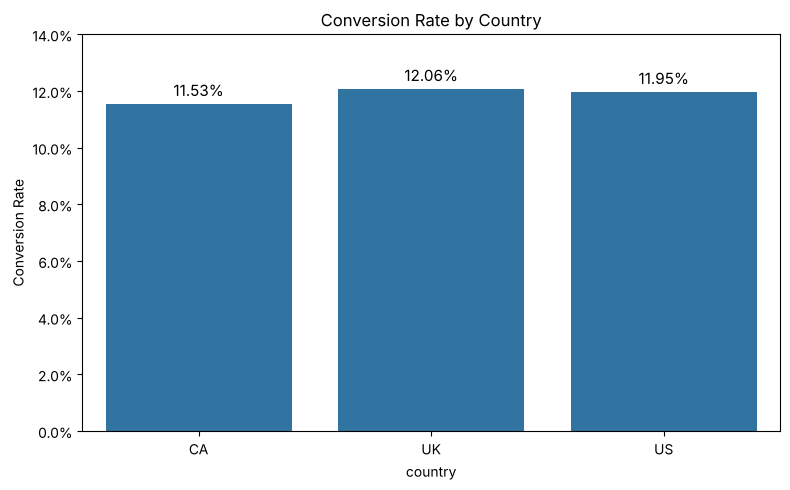

In [21]:
from matplotlib.ticker import PercentFormatter
country_rates = df.groupby('country')['converted'].mean().reset_index()
plt.figure(figsize=(8,5))

ax=sns.barplot(x='country', y='converted', data=country_rates, errorbar=None)

plt.title("Conversion Rate by Country")
plt.ylabel("Conversion Rate")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.ylim(0, 0.14)

for i, row in country_rates.iterrows():
    ax.text(i, row['converted'] + 0.003, f"{row['converted']*100:.2f}%", 
            ha='center', fontsize=11)
plt.tight_layout()
plt.savefig("../visuals/conversion_rate_by_country.png")

plt.show()

In [22]:
df.groupby(['country','group'])['converted'].mean()

country  group    
CA       control      0.118783
         treatment    0.111902
UK       control      0.120022
         treatment    0.121171
US       control      0.120630
         treatment    0.118466
Name: converted, dtype: float64

In [23]:
df.groupby(['country','landing_page'])['converted'].mean()

country  landing_page
CA       new_page        0.111902
         old_page        0.118783
UK       new_page        0.121171
         old_page        0.120022
US       new_page        0.118466
         old_page        0.120630
Name: converted, dtype: float64

### Country-Level Z-Tests

Checking whether the new page performs differently within each country.

In [24]:
rows = []
for country, sub in df.groupby('country'):
    conv = sub.groupby('group')['converted'].agg(['sum', 'count'])
    z, p = proportions_ztest(
        [conv.loc['treatment', 'sum'], conv.loc['control', 'sum']],
        [conv.loc['treatment', 'count'], conv.loc['control', 'count']]
    )
    rows.append({
        'Country': country,
        'Users': len(sub),
        'Old Page Rate (%)': round(conv.loc['control', 'sum'] / conv.loc['control', 'count'] * 100, 2),
        'New Page Rate (%)': round(conv.loc['treatment', 'sum'] / conv.loc['treatment', 'count'] * 100, 2),
        'Z': round(z, 2),
        'P-value': round(p, 3)
    })

pd.DataFrame(rows)

,Country,Users,Old Page Rate (%),New Page Rate (%),Z,P-value
0,CA,14499,11.88,11.19,-1.30,0.195
1,UK,72466,12.00,12.12,0.47,0.635
2,US,203619,12.06,11.85,-1.51,0.132


### Country Segmentation Analysis

The dataset was merged with user country information to examine whether the experiment behaved differently across regions.

User distribution shows that most users are from the United States, followed by the United Kingdom and Canada.

Conversion rate analysis by country shows:
- UK: 12.06%
- US: 11.95%
- CA: 11.53%

Further analysis comparing control and treatment groups within each country indicates that the new landing page performs slightly better in the UK, but the old page performs better in the US and Canada.

The country-level Z-tests confirm none of these differences are statistically significant (US p = 0.132, CA p = 0.195, UK p = 0.635). There is no country where the new page clearly wins.

## Logistic Regression Analysis

Logistic regression is used to examine whether the landing page has a statistically significant effect on conversion when controlling for user country.

In [25]:
import statsmodels.api as sm

In [26]:
df['ab_page'] = df['landing_page'].apply(lambda x: 1 if x == 'new_page' else 0)

In [27]:
country_dummies = pd.get_dummies(df['country'], drop_first=True)

In [28]:
country_dummies.head()

,UK,US
0,False,True
1,False,True
2,False,True
3,False,True
4,False,True


In [29]:
df=df.join(country_dummies)

In [30]:
df.columns

Index(['user_id', 'timestamp', 'group', 'landing_page', 'converted', 'country',
       'ab_page', 'UK', 'US'],
      dtype='str')

In [31]:
df[['UK','US']] = df[['UK','US']].astype(int)

In [32]:
df[['UK','US']].head()

,UK,US
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [33]:
df[['ab_page','UK','US']].dtypes

ab_page    int64
UK         int64
US         int64
dtype: object

In [34]:
logit_model = sm.Logit(df['converted'], sm.add_constant(df[['ab_page','UK','US']]))
result = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.366113
         Iterations 6


In [35]:
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              converted   No. Observations:               290584
Model:                          Logit   Df Residuals:                   290580
Method:                           MLE   Df Model:                            3
Date:                Thu, 29 Oct 2026   Pseudo R-squ.:               2.323e-05
Time:                        16:33:05   Log-Likelihood:            -1.0639e+05
converged:                       True   LL-Null:                   -1.0639e+05
Covariance Type:            nonrobust   LLR p-value:                    0.1760
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0300      0.027    -76.249      0.000      -2.082      -1.978
ab_page       -0.0149      0.011     -1.307      0.191      -0.037       0.007
UK             0.0506      0.028      1.784      0.074      -0.005       0.106
US             0.0408      0.027      1.516      0.130      -0.012       0.093
==============================================================================
"""

### Logistic Regression Analysis

A logistic regression model was used to evaluate whether the landing page influences conversion probability while controlling for user country.

Results:

- The coefficient for the new landing page (ab_page) is -0.0149.
- The p-value for ab_page is 0.191, which is greater than the significance level of 0.05.

This indicates that the new landing page does not have a statistically significant effect on conversion rates.

Country variables (UK and US) also show p-values greater than 0.05, suggesting that user location does not significantly impact conversion probability.

Overall, the logistic regression results support the earlier A/B test findings that the new landing page does not significantly improve conversion rates.

### Statistical Power

Power is the chance the test would detect a real difference of a given size. Here I check the power to detect the difference actually observed.

In [36]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

p_old = convert_old / n_old
p_new = convert_new / n_new
effect = proportion_effectsize(p_new, p_old)

observed_power = NormalIndPower().power(effect_size=effect, nobs1=n_new, ratio=n_old / n_new, alpha=0.05)
print(f"Power to detect the observed difference: {observed_power*100:.1f}%")

# Smallest lift this test could reliably detect (80% power)
mde_effect = NormalIndPower().solve_power(nobs1=n_new, ratio=n_old / n_new, alpha=0.05, power=0.8)
mde_pp = (np.sin(np.arcsin(np.sqrt(p_old)) + mde_effect / 2) ** 2 - p_old) * 100
print(f"Minimum detectable effect at 80% power: about {mde_pp:.2f} percentage points")

Power to detect the observed difference: 25.9%
Minimum detectable effect at 80% power: about 0.34 percentage points


### Final Business Insight

The new landing page does not improve conversion. Across 290,584 users, conversion was 11.88% on the new page vs 12.04% on the old page (p = 0.19, 95% CI [-0.39 pp, +0.08 pp]). The result holds within every country and after controlling for country in a logistic regression.

**Recommendation:** keep the existing landing page. With this traffic, the test could reliably detect a change of about 0.34 percentage points or more, so any real effect of the new page is very small. Future tests should target bigger design changes.